<a href="https://colab.research.google.com/github/rafi1624/PCVK_18_Rafi-Abyantara/blob/main/Week%207.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [79]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [80]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Dummy citra gradien untuk Soal 3 (jika tidak ada gambar spesifik)
img_gradien = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (256, 1))

In [81]:
def convolution2d(image, kernel, stride=1, padding=0):
    if padding > 0:
        padded_image = np.pad(image, pad_width=padding, mode='constant', constant_values=0)
    else:
        padded_image = image

    img_h, img_w = padded_image.shape
    kernel_h, kernel_w = kernel.shape

    out_h = int((img_h - kernel_h) / stride) + 1
    out_w = int((img_w - kernel_w) / stride) + 1

    output = np.zeros((out_h, out_w), dtype=np.float32)

    for i in range(0, out_h):
        for j in range(0, out_w):
            h_start = i * stride
            h_end = h_start + kernel_h
            w_start = j * stride
            w_end = w_start + kernel_w

            region = padded_image[h_start:h_end, w_start:w_end]
            output[i, j] = np.sum(region * kernel)

    # Potong nilai agar di rentang 0-255 dan ubah ke uint8
    output = np.clip(output, 0, 255).astype(np.uint8)

    return output

In [82]:

img = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

In [83]:

#image sharpen
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

array([[  0,   0,   0, ...,   0,   0,   0],
       [  0, 255,   0, ..., 255, 255,   0],
       [  0, 255, 179, ..., 249, 218,   0],
       ...,
       [  0, 255, 255, ..., 159, 183,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], dtype=uint8)
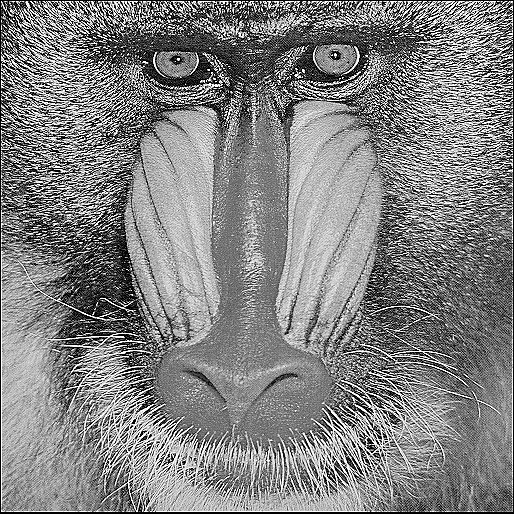

In [84]:

convolution2d(img_gray, kernel_sharpen, 1, 2)

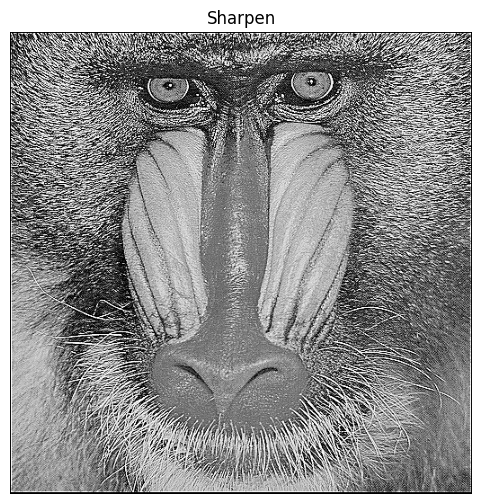

In [85]:
# Sharpen
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

img_sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)

# Konversi output ke numpy array tipe float32
img_sharpen = np.array(img_sharpen, dtype=np.float32)

# Menampilkan hasil
plt.figure(figsize=(6, 6))
plt.imshow(img_sharpen, cmap='gray')
plt.title('Sharpen')
plt.axis('off')
plt.show()

In [ ]:

# Emboss
kernel_emboss = np.array([[-2, -1, 0],
                          [-1, 1, 1],
                          [0, 1, 2]])

img_emboss = convolution2d(img_gray, kernel_emboss, 1, 2)

plt.figure(figsize=(6, 6))
plt.imshow(img_emboss, cmap='gray')
plt.title('Emboss')
plt.show()

In [ ]:
# Left Sobel Edge Detection
kernel_sobel = np.array([[1, 0, -1],
                         [2, 0, -2],
                         [1, 0, -1]])

img_sobel = convolution2d(img_gray, kernel_sobel, 1, 2)

plt.figure(figsize=(6, 6))
plt.imshow(img_sobel, cmap='gray')
plt.title('Left Sobel Edge Detection')
plt.show()


In [ ]:

# Canny Edge Detection (Laplacian Kernel)
kernel_canny = np.array([[-1, -1, -1],
                         [-1, 8, -1],
                         [-1, -1, -1]])

img_canny = convolution2d(img_gray, kernel_canny, 1, 2)

plt.figure(figsize=(6, 6))
plt.imshow(img_canny, cmap='gray')
plt.title('Canny Edge Detection')
plt.show()

In [ ]:

# 21x21 Gaussian Blur
kernel_size = 21
sigma = math.sqrt(kernel_size)

gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gauss_kernel = gaussian_kernel @ gaussian_kernel.transpose()

img_gaussian = convolution2d(img_gray, gauss_kernel, 1, 2)

plt.figure(figsize=(6, 6))
plt.imshow(img_gaussian, cmap='gray')
plt.title('21x21 Gaussian Blur')
plt.show()

2. FILTER LIBRARY DAN FILTER MODERN

In [ ]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

In [ ]:
img = cv.imread("/content/drive/MyDrive/PCVK/Images/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)


In [ ]:
blur = cv.GaussianBlur(img, (7,7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges],
                   ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

In [ ]:
# Filter Modern dari OpenCV
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

# Menampilkan hasil berdampingan
show_side_by_side([img, bilateral, edge_preserve],
                   ["Asli", "Bilateral Filter", "Edge Preserving Filter"])

In [ ]:

#Filter Feature Map yang digunakan pada CNN, Lakukan running code bagian ini beberapa kali dan perhatikan hasilnya
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)

    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()

# Ubah gambar ke tensor
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0

# Hasil CNN
with torch.no_grad():
    features = model(img_tensor)

# Visualisasi feature maps
feature_maps = [features[0,i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ["Asli (Gray)"] + [f"Feature {i+1}" for i in range(len(feature_maps))])


In [ ]:
# ====================
# 1. Beauty Filter
# ====================
# Step 1: Smoothing kulit dengan bilateral filter
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)

# Step 2: Unsharp masking (pertajam mata/bibir)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
sharpened = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)

# Step 3: Brightness & contrast
alpha = 1.2  # contrast
beta = 15    # brightness
beauty = cv.convertScaleAbs(sharpened, alpha=alpha, beta=beta)

# ====================
# 2. Old/Vintage Filter
# ====================
# Step 1: Sepia tone
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)

# Step 2: Vignette
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
kernel = kernel_y * kernel_x.T
mask = kernel / kernel.max()
vignette = np.copy(sepia)
for i in range(3):
    vignette[:,:,i] = vignette[:,:,i] * mask

# Step 3: Noise/Grain
noise = np.random.normal(0, 15, vignette.shape).astype(np.int16)
old_img = np.clip(vignette.astype(np.int16) + noise, 0, 255).astype(np.uint8)

In [ ]:
show_side_by_side([img, beauty, old_img],
                   ["Asli", "Beauty Filter", "Old/Vintage Filter"])

In [ ]:

#Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                            cv.ADAPTIVE_THRESH_MEAN_C,
                            cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

In [ ]:
# Membaca dari jalur lokal yang terdeteksi di runtime Colab
img_path_local = "/content/drive/MyDrive/PCVK/Images/djawatan.jpg"
img = cv.imread(img_path_local)

if img is None:
    print(f"Error: Gagal membaca gambar di {img_path_local}.")
else:
    img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Step 1: Gelapkan (contrast turun, brightness negatif)
    night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

    # Step 2: Tambah bias biru
    blue_tint = np.full_like(night, (50, 0, 100)) # BGR
    night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

    # Step 3: Efek glow di area terang dengan filter2D (blur kernel)
    kernel = np.ones((15,15), np.float32) / 225
    glow = cv.filter2D(night, -1, kernel)

    # Kombinasikan asli + glow
    night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

    show_side_by_side([img, night, night_glow],
                       ["Asli", "Night Filter", "Night + Glow (filter2D)"])

In [ ]:

#Filter Suasana pagi dan Kabut
# ==========================
# Step 1: Kurangi kontras & cerahkan
# ==========================
alpha = 0.9   # contrast
beta = 20     # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# ==========================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# ==========================
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# ==========================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# ==========================
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                   ["Asli", "Pagi", "Pagi + Kabut"])


Tugas Praktikum PCVK

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1a. Load citra grayscale dan tambahkan noise Salt and Pepper
img_gray = cv.imread('/content/drive/MyDrive/PCVK/Gambar/lena.jpg', cv.IMREAD_GRAYSCALE)
if img_gray is None:
    img_gray = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff', cv.IMREAD_GRAYSCALE)

noisy_img = img_gray.copy()
prob = 0.05  # Probabilitas noise (5%)

# Tambahkan noise Salt (putih)
num_salt = np.ceil(prob * img_gray.size * 0.5)
coords = [np.random.randint(0, i - 1, int(num_salt)) for i in img_gray.shape]
noisy_img[tuple(coords)] = 255

# Tambahkan noise Pepper (hitam)
num_pepper = np.ceil(prob * img_gray.size * 0.5)
coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in img_gray.shape]
noisy_img[tuple(coords)] = 0

# 1b. Terapkan Mean Filter (3x3) dan Median Filter (3x3)
mean_filtered = cv.blur(noisy_img, (3, 3))
median_filtered = cv.medianBlur(noisy_img, 3)

# Tampilkan hasil
titles = ['Citra Ber-Noise', 'Mean Filter (3x3)', 'Median Filter (3x3)']
images = [noisy_img, mean_filtered, median_filtered]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')
plt.show()

Analisis Visual (1c):

Mean Filter menghitung nilai rata-rata dari seluruh piksel di dalam tetangga
. Karena noise Salt (255) dan Pepper (0) memiliki nilai ekstrim, nilai ini merusak rata-rata piksel di sekitarnya. Akibatnya, noise tidak hilang sepenuhnya melainkan hanya "dikaburkan" (menjadi bintik-bintik buram abu-abu).
Median Filter mengambil nilai tengah (median) setelah mengurutkan piksel di dalam tetangga
. Karena noise Salt and Pepper berupa nilai ekstrim di ujung atas/bawah, nilai tersebut akan terbuang saat pengurutan. Hasilnya, piksel noise digantikan oleh nilai piksel tetangga yang normal, membuat citra jauh lebih bersih tanpa mengaburkan detail utama.

In [ ]:
# 2a. Buat Kernel Sharpening 3x3 dan 5x5
kernel_sharpen_3x3 = np.array([[ 0, -1,  0],
                               [-1,  5, -1],
                               [ 0, -1,  0]])

kernel_sharpen_5x5 = np.array([[-1, -1, -1, -1, -1],
                               [-1, -1, -1, -1, -1],
                               [-1, -1, 25, -1, -1],
                               [-1, -1, -1, -1, -1],
                               [-1, -1, -1, -1, -1]]) / 9.0

# 2b. Terapkan pada citra yang sedikit buram (diberi GaussianBlur dulu agar buram)
img_src = cv.imread('/content/drive/MyDrive/PCVK/Images/lena.jpg')
if img_src is None:
    img_src = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')

blurry_img = cv.GaussianBlur(img_src, (5, 5), 0)

sharpen_3x3 = cv.filter2D(blurry_img, -1, kernel_sharpen_3x3)
sharpen_5x5 = cv.filter2D(blurry_img, -1, kernel_sharpen_5x5)

# Tampilkan Hasil
titles_2 = ['Citra Buram (Input)', 'Sharpening 3x3', 'Sharpening 5x5']
images_2 = [blurry_img, sharpen_3x3, sharpen_5x5]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.imshow(cv.cvtColor(images_2[i], cv.COLOR_BGR2RGB))
    plt.title(titles_2[i])
    plt.axis('off')
plt.show()

Evaluasi dan Kesimpulan (2c):

Kernel 3 x 3
: Memberikan penajaman tepi (edge enhancement) yang pas dan natural tanpa menghasilkan distorsi tinggi. Noise pada area halus tetap terkontrol.

Kernel 5 x 5
: Menajamkan garis tepi secara sangat agresif, namun menghasilkan over-sharpening, efek halo di sekitar tepi, dan melipatgandakan noise distortion pada area gambar yang rata.

Rekomendasi: Kernel 3 x 3
 adalah pilihan paling optimal untuk penggunaan sehari-hari karena menjaga keseimbangan antara kejelasan tepi dan kontrol tingkat noise.

In [ ]:
# 3a. Fungsi Kustom kartun(image)
def kartun(image):
    # 1. Penghalusan warna dengan Bilateral Filter
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    # 2. Deteksi garis tepi dengan Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                cv.ADAPTIVE_THRESH_MEAN_C,
                                cv.THRESH_BINARY, 9, 9)

    # Konversi edges ke 3-channel BGR agar bisa digabung
    edges_color = cv.cvtColor(edges, cv.COLOR_GRAY2BGR)

    # 3. Penggabungan menggunakan operasi bitwise_and
    cartoon_img = cv.bitwise_and(color, edges_color)
    return cartoon_img

# 3b. Tampilkan hasil citra asli dan efek kartun bersebelahan
img_input = cv.imread('/content/drive/MyDrive/PCVK/Images/lena.jpg')
if img_input is None:
    img_input = cv.imread('/content/drive/MyDrive/PCVK/Images/mandrill.tiff')

cartoon_result = kartun(img_input)

# Visualisasi
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_input, cv.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(cartoon_result, cv.COLOR_BGR2RGB))
plt.title('Efek Kartun (Kartun Custom)')
plt.axis('off')

plt.show()

Modul P7